# The coherence and its uncertainty

This notebook explains how Stingray estimates the **coherence** between two energy bands, and
how it calculates its **error bars**. It then shows, with simulations, that these error bars
can be trusted: from weak to strong signals, and from no coherence to full coherence.

The last part introduces a variant that crosses **two detectors** observing the same source
(e.g. the two NuSTAR modules). This variant does not need to know the Poisson noise level,
which is useful when instrumental effects like dead time distort it.

The notebook needs a version of Stingray where `intrinsic_coherence` accepts
`return_interval` and `cross_detector_coherence` exists.

**Contents**

1. What the coherence measures
2. Poisson noise and the bias of the coherence
3. Error bars, and how to check them: *coverage*
4. A better interval
5. Proof that it works
6. Two detectors: no noise level to subtract
7. Summary and recipe

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy import optimize, stats

from stingray import AveragedCrossspectrum, EventList, Lightcurve
from stingray.crossspectrum import cross_detector_spectral_matrix
from stingray.filters import get_deadtime_mask
from stingray.fourier import cross_detector_coherence, intrinsic_coherence, poisson_level

plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(20261111)

## 1. What the coherence measures

Take the light curves of the same source in two energy bands, "soft" (band 1) and "hard"
(band 2). Split them into $m$ segments of equal length, and calculate the Fourier transform of
each segment. At a given frequency $f$, each segment gives a complex number for each band: the
**Fourier amplitudes** $A_1$ and $A_2$. Their modulus tells how strong the variability at
that frequency is, and their argument (the angle in the complex plane) tells when the
oscillation peaks.

From the amplitudes we build:

* the **power spectra** $P_1 = |A_1|^2$ and $P_2 = |A_2|^2$, which measure the variability
  in each band;
* the **cross spectrum** $C = A_1^* A_2$ (the star means complex conjugate). Its argument is
  the **phase lag** between the bands: the difference of their angles.

The **coherence** is

$$
\gamma^2 = \frac{|\langle C \rangle|^2}{\langle P_1\rangle \langle P_2 \rangle},
$$

where $\langle \cdot \rangle$ is the average over the $m$ segments. It tells how much of the
variability of one band can be predicted from the other with a *linear filter*: a time
delay, a smoothing, a change of amplitude. If the hard band is just a delayed copy of the
soft band, $\gamma^2 = 1$. If the two bands vary independently, $\gamma^2 = 0$.

Why the average? In a single segment $|C|^2 = |A_1|^2 |A_2|^2 = P_1 P_2$, so the ratio is
always exactly 1, whatever the bands do. The information is in how the phase lag changes from
segment to segment. If it is always the same, the cross spectra of all segments point in the
same direction and their average is long. If it changes randomly, they point in random
directions, and their average shrinks.

### A toy model

To see this, we build a hard band from two parts: a copy of the soft band, with a phase lag,
carrying a fraction $c$ of the hard-band variability, and an unrelated signal carrying the rest:

$$
A_2 = \sqrt{c}\, A_1\, e^{-i\phi} + \sqrt{1 - c}\, A_{\rm other}.
$$

The coherence of this model is exactly $c$. For noise-like variability, as in accreting
compact objects, the Fourier amplitudes at a given frequency behave like random complex
numbers, whose real and imaginary parts follow a Gaussian distribution. So we can simulate the
amplitudes directly, without simulating light curves. The function below does this, adding
independent Poisson noise of power $N$ to each band (more on noise in section 2).

In [2]:
def complex_gaussian(size):
    # Random complex numbers with Gaussian real and imaginary parts, and <|z|^2> = 1
    return (rng.normal(size=size) + 1j * rng.normal(size=size)) / np.sqrt(2)


def simulate_amplitudes(signal_power, coherence, m, n_sim, noise_power=1.0, phase=0.5):
    # Fourier amplitudes of two bands at one frequency: m segments, repeated n_sim times.
    # Both bands have the same signal power; noise_power is the Poisson noise level.
    soft = complex_gaussian((n_sim, m))
    other = complex_gaussian((n_sim, m))
    hard = np.sqrt(coherence) * soft * np.exp(-1j * phase) + np.sqrt(1 - coherence) * other
    a1 = np.sqrt(signal_power) * soft + np.sqrt(noise_power) * complex_gaussian((n_sim, m))
    a2 = np.sqrt(signal_power) * hard + np.sqrt(noise_power) * complex_gaussian((n_sim, m))
    return a1, a2


def averaged_spectra(a1, a2):
    # Cross spectrum and power spectra, averaged over the segments (last axis)
    cross = np.mean(np.conj(a1) * a2, axis=-1)
    return cross, np.mean(np.abs(a1) ** 2, axis=-1), np.mean(np.abs(a2) ** 2, axis=-1)

Without noise, let us measure the coherence of the toy model with $c = 0.6$ for an increasing
number of segments. Each point is the average over 2000 simulations, and the shaded band
contains the central 68% of them.

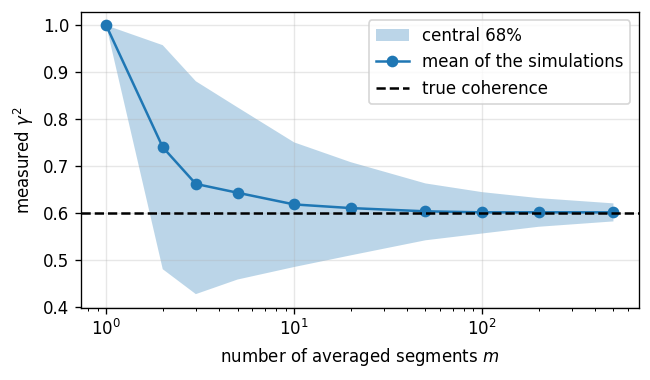

In [3]:
true_c = 0.6
ms = np.array([1, 2, 3, 5, 10, 20, 50, 100, 200, 500])
raw = []
for m in ms:
    cross, p1, p2 = averaged_spectra(*simulate_amplitudes(1.0, true_c, m, 2000, noise_power=0))
    raw.append(np.abs(cross) ** 2 / (p1 * p2))
raw = np.array(raw)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.fill_between(ms, *np.percentile(raw, [16, 84], axis=1), alpha=0.3, label="central 68%")
ax.plot(ms, raw.mean(axis=1), "o-", label="mean of the simulations")
ax.axhline(true_c, color="k", ls="--", label="true coherence")
ax.set(xscale="log", xlabel="number of averaged segments $m$", ylabel=r"measured $\gamma^2$")
ax.legend()
plt.show()

With one segment the coherence is always 1. With more segments it approaches the true value
from above, and the scatter shrinks. The measured coherence is **biased**: on average it is
larger than the true value, by an amount that decreases as $1/m$. The next section explains
where this comes from.

## 2. Poisson noise and the bias of the coherence

Real light curves contain Poisson noise (counting noise), which is independent in the two
bands. It adds a constant **noise level** $N$ to each power spectrum, and it makes the bands
look less coherent than the source is. Vaughan & Nowak (1997, ApJ 474, L43; "VN97" below)
proposed to correct for it. Stingray's `intrinsic_coherence` uses an improved version of their
**intrinsic coherence**:

$$
\gamma^2 = \frac{|\langle C \rangle|^2 - b^2}{S_1 S_2 - c^2}.
$$

The terms are:

* $S_1 = \langle P_1\rangle - N_1$ and $S_2 = \langle P_2\rangle - N_2$: the powers of the
  source alone, after subtracting the noise levels.
* $b^2 = \langle P_1\rangle \langle P_2\rangle / m$: the **bias** of the numerator.
* $c^2 = \max(|\langle C \rangle|^2 - b^2, 0) / m$: a smaller correction of the denominator.

### Where $b^2$ comes from

$\langle C \rangle$ is an average of random complex numbers, so it scatters around its true
value $C_{\rm true}$. Write $\langle C \rangle = C_{\rm true} + \delta$, with $\delta$ the
random error. Then

$$
|\langle C \rangle|^2 = |C_{\rm true}|^2 + 2\,{\rm Re}(C_{\rm true}^*\delta) + |\delta|^2.
$$

The middle term averages to zero, but $|\delta|^2$ is never negative: on average,
$|\langle C \rangle|^2$ is larger than $|C_{\rm true}|^2$ by the **variance** of
$\langle C \rangle$ (the average of $|\delta|^2$). This is the same reason why the average of
$x^2$ is larger than the square of the average of $x$. For Gaussian Fourier amplitudes this
variance is exactly $\langle P_1\rangle \langle P_2\rangle / m$. It contains the noise, but
also the part of the source variability that is *not* coherent between the bands. VN97's bias
term only contained the noise.

The cleanest way to see the bias is with no coherence at all. Then $C_{\rm true} = 0$, so
$|\langle C\rangle|^2 = |\delta|^2$, which should average to $b^2$. In fact, the squared modulus
of a complex Gaussian number follows an **exponential distribution**, whose mean is its
variance:

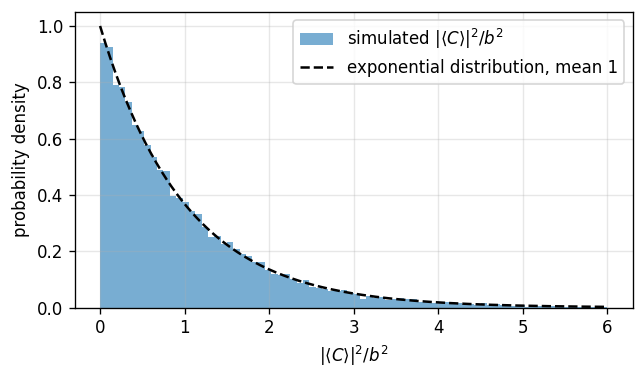

Mean of |<C>|^2 / b^2: 0.991 (expected: 1)


In [4]:
m = 50
cross, p1, p2 = averaged_spectra(*simulate_amplitudes(1.0, 0.0, m, 20000))
b2 = p1 * p2 / m
x = np.abs(cross) ** 2 / b2  # |<C>|^2 in units of its expected bias

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(x, bins=80, range=(0, 6), density=True, alpha=0.6, label=r"simulated $|\langle C\rangle|^2 / b^2$")
grid = np.linspace(0, 6, 200)
ax.plot(grid, np.exp(-grid), "k--", label="exponential distribution, mean 1")
ax.set(xlabel=r"$|\langle C\rangle|^2 / b^2$", ylabel="probability density")
ax.legend()
plt.show()
print(f"Mean of |<C>|^2 / b^2: {x.mean():.3f} (expected: 1)")

### The bias, old and new

Let us compare, as a function of the true coherence, the average of three estimates:

* no bias correction at all, only the noise levels subtracted in the denominator;
* VN97's bias term, $n^2 = (\langle P_1\rangle\langle P_2\rangle - S_1 S_2)/m$, as previously
  implemented in Stingray (which also set negative values to 0);
* the new estimate.

Here the source power is 3 times the noise power in both bands, and $m = 20$. (With a weaker
source, the noise-subtracted powers in the denominator are sometimes close to zero, and averages
of the ratio become dominated by a few huge values.)

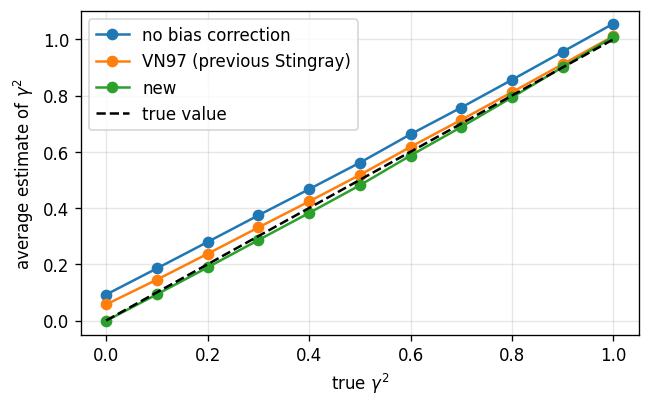

In [5]:
def vn97_old(cross, p1, p2, n1, n2, m):
    # Intrinsic coherence and its uncertainty as previously implemented in Stingray (VN97 eq. 8)
    s1, s2 = p1 - n1, p2 - n2
    too_low = (s1 <= 3 * n1 / np.sqrt(m)) | (s2 <= 3 * n2 / np.sqrt(m))
    nsq = 0.0 if m > 500 else (p1 * p2 - s1 * s2) / m
    num = np.abs(cross) ** 2 - nsq
    coh = num / (s1 * s2)
    err = coh / np.sqrt(m) * np.sqrt(
        2 * nsq**2 * m / (num - nsq) ** 2
        + (n1 / s1) ** 2
        + (n2 / s2) ** 2
        + 2 * ((1 - coh) / coh**1.5) ** 2
    )
    coh = np.where(num < 0, 0.0, coh)
    err = np.where(num < 0, np.nan, err)
    return np.where(too_low, np.nan, coh), np.where(too_low, np.nan, err)


m, signal_power = 20, 3.0
true_values = np.linspace(0, 1, 11)
means = {"no bias correction": [], "VN97 (previous Stingray)": [], "new": []}
with warnings.catch_warnings(), np.errstate(all="ignore"):
    warnings.simplefilter("ignore")
    for c in true_values:
        cross, p1, p2 = averaged_spectra(*simulate_amplitudes(signal_power, c, m, 20000))
        means["no bias correction"].append(np.mean(np.abs(cross) ** 2 / ((p1 - 1) * (p2 - 1))))
        means["VN97 (previous Stingray)"].append(np.nanmean(vn97_old(cross, p1, p2, 1.0, 1.0, m)[0]))
        means["new"].append(np.nanmean(intrinsic_coherence(cross, p1, p2, 1.0, 1.0, m)))

fig, ax = plt.subplots(figsize=(6, 3.5))
for label, values in means.items():
    ax.plot(true_values, values, "o-", label=label)
ax.plot([0, 1], [0, 1], "k--", label="true value")
ax.set(xlabel=r"true $\gamma^2$", ylabel=r"average estimate of $\gamma^2$", ylim=(-0.05, 1.1))
ax.legend()
plt.show()

Without a bias correction, the estimate is far too high. VN97's correction helps but leaves
part of the bias, especially at low coherence (where the incoherent signal it leaves out is
largest). The old implementation also replaced negative values with 0, which pushes the
average up. The new estimate is on the true line at zero coherence, and within about 0.02
elsewhere. This small remaining bias comes from dividing two noisy quantities, it shrinks
like $1/m$, and it is several times smaller than the error bars (about 0.1 here).

The new estimate can be **negative**. If the bands are not coherent, the measured
$|\langle C\rangle|^2$ is sometimes smaller than its average $b^2$, as in the histogram above.
Keeping these values is what makes the average right: if we replaced them with zero, the
average would be too large. When the estimate is negative, the honest conclusion is "the
coherence is small", and the error bar (next section) says how small.

## 3. Error bars, and how to check them: *coverage*

A 1-sigma error bar (or **1-sigma interval**) should contain the true value about 68% of the
time, as for a Gaussian distribution. The fraction of times it actually does is called its
**coverage**. With simulations we know the true value, so we can measure the coverage: simulate
the same observation many times, calculate the interval each time, and count how often it
contains the truth.

* coverage of about 0.68: the error bars are right;
* coverage much lower: they are too small, and we claim more precision than we have;
* coverage much higher: they are too large, and we are throwing information away.

The previous implementation used VN97's eq. 8 for the error bar. Let us measure its coverage at
a few combinations of the true coherence, with source power equal to noise power and $m = 50$:

In [6]:
def coverage(lower, upper, truth):
    # Fraction of intervals that contain the truth (an undefined interval counts as a miss)
    return np.mean((lower <= truth) & (truth <= upper))


m, n_sim = 50, 4000
# an error bar that cannot be calculated (NaN) counts as a miss
print("true coherence | coverage of the old error bar | fraction of undefined error bars")
with warnings.catch_warnings(), np.errstate(all="ignore"):
    warnings.simplefilter("ignore")
    for c in (0.0, 0.1, 0.3, 0.6, 0.9):
        cross, p1, p2 = averaged_spectra(*simulate_amplitudes(1.0, c, m, n_sim))
        coh, err = vn97_old(cross, p1, p2, 1.0, 1.0, m)
        print(f"{c:14.1f} | {coverage(coh - err, coh + err, c):29.2f} | {np.mean(np.isnan(err)):.2f}")

true coherence | coverage of the old error bar | fraction of undefined error bars
           0.0 |                          0.46 | 0.53
           0.1 |                          0.69 | 0.24
           0.3 |                          0.76 | 0.06
           0.6 |                          0.65 | 0.03
           0.9 |                          0.55 | 0.03


The old error bars cover the true value between 46% and 76% of the time, and at low coherence
many of them cannot be calculated at all. This is one of the *best* cases: the full map in
section 5 shows coverages from 0% to 100%. Checking VN97's derivation, we found
a few problems (listed in the Stingray documentation). Two typos make one term too small by a
factor of about $m$, a relative error is used as an absolute one, and some terms are missing.

There is also a deeper problem, which affects any error bar of the form "estimate $\pm\,\sigma$
calculated at the estimate". Near zero coherence, the scatter of the estimate depends strongly
on the true value. If the measured coherence happens to be close to zero, a formula evaluated at
the measured value gives a tiny error bar, exactly when we should be most careful.

## 4. A better interval

The idea is to turn the question around. Instead of asking "how much does the estimate scatter
around the measured value?", we ask, for every possible true value $\gamma^2_0$: **"if the truth
were $\gamma^2_0$, would our measurement be surprising?"**

1. For each candidate $\gamma^2_0$, calculate how much the estimate would scatter if
   $\gamma^2_0$ were the truth: its standard deviation $\sigma(\gamma^2_0)$.
2. Keep $\gamma^2_0$ if the measured value $\hat\gamma^2$ (the hat marks the measured value) is
   within one standard deviation of it: $|\hat\gamma^2 - \gamma^2_0| \le \sigma(\gamma^2_0)$.
3. The interval is the range of kept values.

Statisticians call this *inverting a test*: each candidate value is "tested" against the data,
and the interval collects the candidates that pass. The key difference from the usual error bar
is that $\sigma$ is calculated for each candidate, not at the noisy measured value. The figure
shows the construction for one measurement.

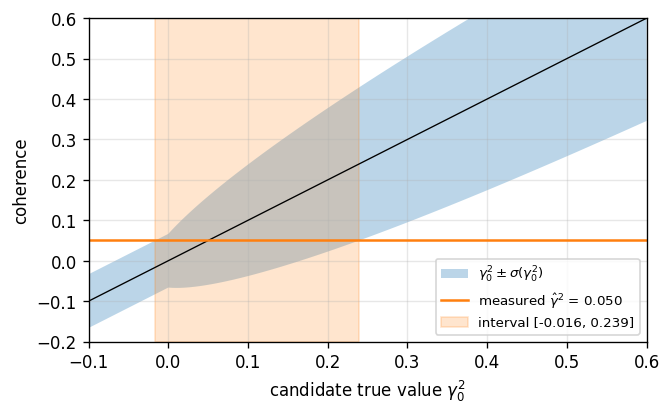

In [7]:
from stingray.fourier import _coherence_score_variance  # the sigma^2 used by Stingray

m, p, n = 50, 2.0, 1.0  # measured powers: source power 1 + noise level 1, in both bands
measured = 0.05
candidates = np.linspace(-0.1, 0.6, 400)
# below zero, Stingray uses the scatter at zero
sigma = np.sqrt(_coherence_score_variance(np.maximum(candidates, 0), p, p, p - n, p - n, m))
coh, lower, upper = intrinsic_coherence(
    np.sqrt(measured * (p - n) ** 2 + p * p / m), p, p, n, n, m, return_interval=True
)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.fill_between(candidates, candidates - sigma, candidates + sigma, alpha=0.3,
                label=r"$\gamma^2_0 \pm \sigma(\gamma^2_0)$")
ax.plot(candidates, candidates, "k-", lw=0.8)
ax.axhline(coh, color="C1", label=rf"measured $\hat\gamma^2$ = {coh:.3f}")
ax.axvspan(lower, upper, color="C1", alpha=0.2, label=f"interval [{lower:.3f}, {upper:.3f}]")
ax.set(xlabel=r"candidate true value $\gamma^2_0$", ylabel="coherence", xlim=(-0.1, 0.6), ylim=(-0.2, 0.6))
ax.legend(loc="lower right", fontsize=8)
plt.show()

The interval contains the candidates for which the horizontal line (the measurement) lies inside
the shaded band. It is **asymmetric**: it extends further above the measured value than below,
because the scatter grows with the coherence near zero. It also includes slightly negative
values: below zero, Stingray uses the scatter calculated at zero.

### The standard deviation $\sigma(\gamma^2_0)$

For Gaussian Fourier amplitudes, all the averages and their correlations can be calculated
exactly. Calling $r_1 = N_1/S_1$ and $r_2 = N_2/S_2$ the noise-to-signal ratios of the two bands,
and $q = r_1 + r_2 + r_1 r_2$, the variance (the square of $\sigma$) is

$$
\sigma^2(\gamma^2_0) =
\underbrace{\frac{2\gamma^2_0 (1 - \gamma^2_0)(1 - \gamma^2_0 + q) + (\gamma^2_0)^2 (r_1 + r_2)^2}{m}}_{\text{first order}}
+ \underbrace{\left(\kappa\, \frac{\langle P_1\rangle\langle P_2\rangle - \gamma^2_0 S_1 S_2}{m S_1 S_2}\right)^2}_{\text{second order}}.
$$

* The **first-order** term is the usual propagation of errors from the lab courses: it
  describes how small fluctuations of the cross spectrum and of the two powers move the ratio,
  including the fact that these fluctuations are correlated. Without noise ($r_1 = r_2 = 0$) it
  gives the classic result $2\gamma^2(1-\gamma^2)^2/m$. At full coherence it reduces to
  $\sigma = (r_1 + r_2)/\sqrt{m}$: only the noise makes the coherence scatter.
* The first-order term vanishes at $\gamma^2_0 = 0$, but the estimate still scatters there:
  we saw that $|\langle C\rangle|^2$ then follows an exponential distribution. The
  **second-order** term describes this. Its numerator is the incoherent part of the variance of
  the cross spectrum, and it vanishes for a perfectly coherent signal without noise.

### Where $\kappa = 0.83$ comes from

At zero coherence, $|\langle C\rangle|^2$ follows an exponential distribution with mean $b^2$,
and the estimate subtracts $b^2$. We want the interval $\pm\sigma$ around the mean to contain 68.27%
of the distribution, as for a Gaussian. For an exponential distribution with mean 1, the
probability to fall within $1 \pm \kappa$ is $e^{-(1-\kappa)} - e^{-(1+\kappa)} = 2 e^{-1} \sinh\kappa$.
Setting it to 0.6827 gives $\kappa \approx 0.83$:

kappa = 0.829


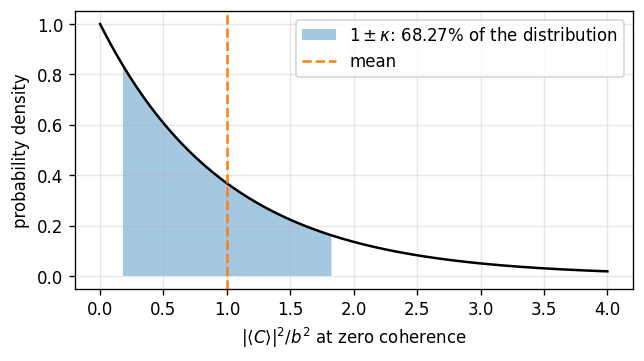

In [8]:
kappa = optimize.brentq(lambda k: 2 * np.exp(-1) * np.sinh(k) - 0.6827, 0, 1)
print(f"kappa = {kappa:.3f}")

grid = np.linspace(0, 4, 400)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(grid, np.exp(-grid), "k-")
inside = (grid > 1 - kappa) & (grid < 1 + kappa)
ax.fill_between(grid[inside], np.exp(-grid[inside]), alpha=0.4, label=r"$1 \pm \kappa$: 68.27% of the distribution")
ax.axvline(1, color="C1", ls="--", label="mean")
ax.set(xlabel=r"$|\langle C\rangle|^2 / b^2$ at zero coherence", ylabel="probability density")
ax.legend()
plt.show()

### Values outside [0, 1]

Like the estimate, the interval is not restricted to the range 0 to 1. An interval entirely
below zero means that the cross spectrum is weaker than expected from noise alone: the data are
consistent with no coherence, and a bit unlucky. Restricting the interval to [0, 1] would make it
shrink to the single point [0, 0] in such cases, falsely suggesting a perfect measurement. The
candidate values are searched up to 2: an upper end of 2 means that the data cannot constrain
the coherence from above.

### Using it

`intrinsic_coherence` returns the interval with `return_interval=True`, and half its width with
`return_uncertainty=True`, which is convenient for plots with symmetric error bars:

In [9]:
cross, p1, p2 = averaged_spectra(*simulate_amplitudes(1.0, 0.3, 50, 5))
coh, lower, upper = intrinsic_coherence(cross, p1, p2, 1.0, 1.0, 50, return_interval=True)
coh, err = intrinsic_coherence(cross, p1, p2, 1.0, 1.0, 50, return_uncertainty=True)
for values in zip(coh, lower, upper, err):
    print("coherence {:6.3f}, interval [{:6.3f}, {:6.3f}], half width {:.3f}".format(*values))

coherence  0.474, interval [ 0.272,  0.750], half width 0.239
coherence  0.149, interval [ 0.043,  0.370], half width 0.163
coherence  0.195, interval [ 0.067,  0.447], half width 0.190
coherence  0.150, interval [ 0.053,  0.336], half width 0.142
coherence  0.351, interval [ 0.184,  0.597], half width 0.206


## 5. Proof that it works

We now measure the coverage of the old error bars and of the new interval on a grid:

* source-to-noise power ratio $S/N$ from 0.3 (the source is weaker than the noise in each
  frequency bin) to 10;
* true coherence from 0 to 1;
* $m$ = 10, 50 and 300 averaged segments (or segments times frequency bins).

Each square shows the coverage measured over 2000 simulations; its statistical uncertainty is
about 0.01. White is perfect (0.68), red means error bars that are too small, blue too large.
As before, an old error bar that cannot be calculated counts as a miss; for the new interval,
we skip the (rarer) cases where the estimate itself is undefined, and count them separately.

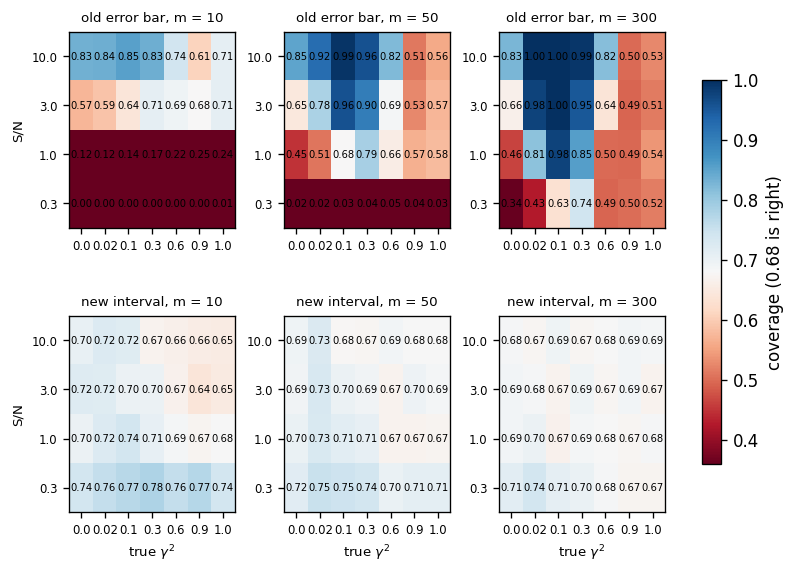

In [10]:
snrs = [0.3, 1.0, 3.0, 10.0]
cohs = [0.0, 0.02, 0.1, 0.3, 0.6, 0.9, 1.0]
segments = [10, 50, 300]
n_sim = 2000

cov_old = np.zeros((len(segments), len(snrs), len(cohs)))
cov_new = np.zeros_like(cov_old)
undefined_new = np.zeros_like(cov_old)
with warnings.catch_warnings(), np.errstate(all="ignore"):
    warnings.simplefilter("ignore")
    for i, m in enumerate(segments):
        for j, snr in enumerate(snrs):
            for k, c in enumerate(cohs):
                cross, p1, p2 = averaged_spectra(*simulate_amplitudes(snr, c, m, n_sim))
                coh, err = vn97_old(cross, p1, p2, 1.0, 1.0, m)
                cov_old[i, j, k] = coverage(coh - err, coh + err, c)
                _, lower, upper = intrinsic_coherence(cross, p1, p2, 1.0, 1.0, m, return_interval=True)
                defined = ~np.isnan(lower)  # NaN where a power is not above the noise level
                undefined_new[i, j, k] = 1 - defined.mean()
                cov_new[i, j, k] = coverage(lower[defined], upper[defined], c)


def coverage_maps(maps, titles, ylabels, xlabels, xticks, yticks):
    fig, axes = plt.subplots(len(maps), len(maps[0]), figsize=(8, 2.6 * len(maps)), squeeze=False)
    for row, (row_maps, row_title) in enumerate(zip(maps, titles)):
        for col, cov in enumerate(row_maps):
            ax = axes[row, col]
            im = ax.imshow(cov, cmap="RdBu", vmin=0.36, vmax=1.0, origin="lower", aspect="auto")
            for (y, x), value in np.ndenumerate(cov):
                ax.text(x, y, f"{value:.2f}", ha="center", va="center", fontsize=6)
            ax.set_xticks(range(len(xticks)), xticks, fontsize=7)
            ax.set_yticks(range(len(yticks)), yticks, fontsize=7)
            ax.set_title(f"{row_title}, {xlabels[col]}", fontsize=8)
            ax.grid(False)
        axes[row, 0].set_ylabel(ylabels, fontsize=8)
    for ax in axes[-1]:
        ax.set_xlabel(r"true $\gamma^2$", fontsize=8)
    fig.subplots_adjust(hspace=0.45, wspace=0.3)
    fig.colorbar(im, ax=axes, label="coverage (0.68 is right)", shrink=0.8)
    plt.show()


coverage_maps(
    [list(cov_old), list(cov_new)],
    ["old error bar", "new interval"],
    "S/N",
    [f"m = {m}" for m in segments],
    cohs,
    snrs,
)

The old error bars range from always missing to always containing the true value, depending on
the case. When the source is weaker than the noise, they can almost never be calculated. The
new interval stays close to 0.68 everywhere. It is a bit conservative (coverage up to about
0.78) only when the source is much weaker than the noise and few segments are averaged, where
the coherence can hardly be measured. In those cases the estimate is also often undefined,
because a measured power falls below the noise level:

In [11]:
print("Fraction of undefined estimates (a power not above its noise level), S/N = 0.3:")
for i, m in enumerate(segments):
    print(f"  m = {m:3d}: {undefined_new[i, 0].mean():.2f}")
print(f"Coverage of the new interval: {cov_new.min():.2f} - {cov_new.max():.2f}, "
      f"mean distance from 0.68: {np.mean(np.abs(cov_new - 0.68)):.3f}")

Fraction of undefined estimates (a power not above its noise level), S/N = 0.3:
  m =  10: 0.42
  m =  50: 0.08
  m = 300: 0.00
Coverage of the new interval: 0.64 - 0.78, mean distance from 0.68: 0.025


## 6. Two detectors: no noise level to subtract

The intrinsic coherence needs the noise levels $N_1$ and $N_2$. For a pure Poisson process they
are known (e.g. 2 in Leahy normalization), but instrumental effects can change them. A common one
is **dead time**: after recording a photon, a detector is "blind" for a short time (2.5 ms for
NuSTAR). This lowers the noise level, and also changes its shape with frequency in a way that
depends on the count rate. Even small errors in $N$ matter a lot when the source is weaker than
the noise: if $N$ is 10 times $S$, a 5% error in $N$ is a 50% error in $S = \langle P\rangle - N$.

When two independent detectors observe the same source at the same time, such as the two NuSTAR
modules, we can avoid the noise level altogether. With $A$ and $B$ the Fourier amplitudes of the
two detectors, the **cospectrum** ${\rm Re}\langle A^* B\rangle$ contains the source variability,
which the two detectors share, but not the Poisson noise, which is independent in the two
detectors and averages out (Bachetti et al. 2015). Stingray's
`cross_detector_spectral_matrix` builds this crossing for two energy bands:

$$
S_{11} = {\rm Re}\langle A_1^* B_1\rangle, \qquad
S_{22} = {\rm Re}\langle A_2^* B_2\rangle, \qquad
S_{12} = \tfrac{1}{2}\langle A_1^* B_2 + B_1^* A_2\rangle.
$$

$S_{11}$ and $S_{22}$ replace the noise-subtracted powers, and $S_{12}$ replaces the cross
spectrum, using both ways of crossing bands and detectors. `cross_detector_coherence` then
calculates

$$
\gamma^2 = \frac{|S_{12}|^2 - b^2}{S_{11} S_{22} - c^2}, \qquad
b^2 = \frac{p_{A1} p_{B2} + p_{B1} p_{A2} + 2 S_{11} S_{22}}{4m}, \qquad
c^2 = \frac{\max(|S_{12}|^2 - b^2, 0)}{m},
$$

where $p_{A1} = \langle|A_1|^2\rangle$ etc. are the ordinary power spectra of each detector in
each band, *including* their noise, whatever its level: they are only needed to calculate the
bias $b^2$, and the matrix provides them. The bias has the same origin as before. The interval is
built in the same way, with a standard deviation that accounts for each detector's own noise.

### A dead-time experiment

We simulate a NuSTAR-like observation of a source with a broad noise-like variability component
(a Lorentzian centred at zero frequency, with half width 0.3 Hz and 15% rms), seen by two
detectors with 2.5 ms dead time. Each detector records 20 counts/s in each band; the soft and
hard bands have a true coherence of 0.6. Dead time is applied to all the photons of a detector
together, whatever their energy, as in a real instrument; the live time is about 91%.

In [12]:
T, dt, deadtime, rate, rms, hwhm, true_c = 65536.0, 1 / 64, 2.5e-3, 20.0, 0.15, 0.3, 0.6

n_bins = int(T / dt)
times = np.arange(n_bins) * dt
freq = np.fft.rfftfreq(n_bins, dt)[1:]
lorentzian = 1 / (1 + (freq / hwhm) ** 2)


def red_noise_amplitudes():
    return complex_gaussian(freq.size) * np.sqrt(lorentzian)


soft_amp, other_amp = red_noise_amplitudes(), red_noise_amplitudes()
hard_amp = np.sqrt(true_c) * soft_amp * np.exp(-0.5j) + np.sqrt(1 - true_c) * other_amp
model_rates = []
for amplitudes in (soft_amp, hard_amp):
    lc = np.fft.irfft(np.r_[0, amplitudes], n=n_bins)
    model_rates.append((1 + lc / lc.std() * rms) * rate)  # counts/s, with 15% rms


def detector_events(deadtime):
    # Photon arrival times of one detector, as two event lists (soft, hard), after dead time
    arrivals = []
    for r in model_rates:
        counts = rng.poisson(r * dt)
        arrivals.append(np.repeat(times, counts) + rng.uniform(0, dt, counts.sum()))
    all_times = np.concatenate(arrivals)
    band = np.concatenate([np.zeros(arrivals[0].size), np.ones(arrivals[1].size)])
    order = np.argsort(all_times)
    all_times, band = all_times[order], band[order]
    if deadtime > 0:  # dead time acts on all photons, whatever their energy
        recorded = get_deadtime_mask(all_times, deadtime, paralyzable=False)
        all_times, band = all_times[recorded], band[recorded]
    return [EventList(all_times[band == b], gti=[[0, T]]) for b in (0, 1)]


(soft_a, hard_a), (soft_b, hard_b) = detector_events(deadtime), detector_events(deadtime)
print(f"Live fraction: {soft_a.time.size / (rate * T):.3f}")

Live fraction: 0.909


First, the noise level. Far above the source variability, the power spectrum of one detector
should sit at the noise level. With dead time, it is lower than the standard Poisson formula
predicts:

In [13]:
segment_size = 64.0
single = AveragedCrossspectrum(soft_a, hard_a, segment_size=segment_size, dt=dt, norm="frac", silent=True)
expected_noise = poisson_level("frac", meanrate=soft_a.time.size / T)
measured_noise = single.pds1.power[single.freq > 16].mean()
print(f"Noise level of the soft band: measured {measured_noise:.4f}, Poisson formula {expected_noise:.4f}")
high = single.freq > 16
print(f"Cross spectrum of the two bands above 16 Hz: {single.power[high].real.mean():.4f} "
      f"+- {single.power[high].real.std() / np.sqrt(high.sum()):.4f} (expected without dead time: 0)")
print(f"Source power at 0.1-0.3 Hz: {single.pds1.power[(single.freq > 0.1) & (single.freq < 0.3)].mean() - measured_noise:.4f}")

Noise level of the soft band: measured 0.1016, Poisson formula 0.1100
Cross spectrum of the two bands above 16 Hz: -0.0086 +- 0.0001 (expected without dead time: 0)
Source power at 0.1-0.3 Hz: 0.0253


The formula overestimates the noise level by about 8%, while the source power in the most
variable frequencies is only a quarter of the noise level. There is a second, subtler effect:
the noise of the two bands is no longer independent. A soft photon makes the detector blind to
the hard photons that follow it, and vice versa, so the two bands of the same detector have
slightly *anticorrelated* noise. Their cross spectrum, which should average to zero at high
frequency, is negative instead. Neither effect exists between two different detectors.

Now we calculate the coherence in
frequency bins, in three ways:

* **single detector**, the intrinsic coherence of detector A, with the standard Poisson noise
  levels;
* **two detectors**, the cross-detector coherence;
* the **reference**: the coherence of the source *as recorded*, calculated from the noise-free
  model count rates multiplied by the live fraction.

Why not just compare with 0.6? Dead time does not only change the noise: it also slightly mixes
the two bands of the source signal. When the soft count rate goes up, the detector is blind more
often and records fewer hard photons, so the recorded hard light curve contains a small negative
copy of the soft one, and vice versa. Here this lowers the coherence from 0.6 to about 0.54. This
is a real change of the recorded signal, which no noise treatment can undo; the reference
includes it.

To get enough statistics, we average the spectra over logarithmically spaced frequency bins.
When averaging, the number of averaged values is the number of segments times the number of
frequency bins.

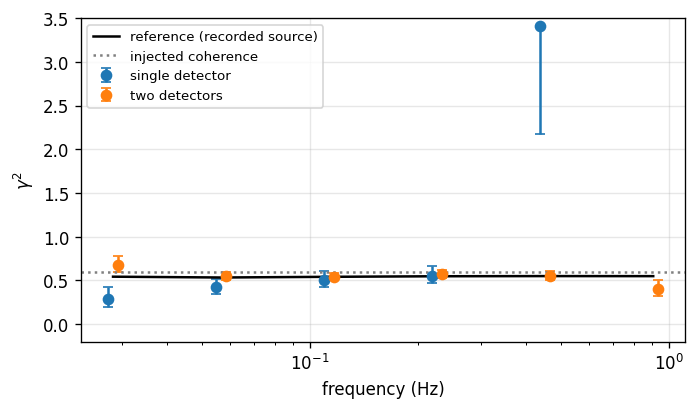

frequency (Hz) | single detector       | two detectors         | reference
         0.028 |  0.29 [ 0.20,  0.43] |  0.68 [ 0.59,  0.77] | 0.54
         0.057 |  0.42 [ 0.34,  0.52] |  0.55 [ 0.50,  0.60] | 0.53
         0.113 |  0.50 [ 0.42,  0.60] |  0.54 [ 0.50,  0.58] | 0.54
         0.226 |  0.55 [ 0.46,  0.66] |  0.57 [ 0.53,  0.61] | 0.55
         0.453 |  3.41 [ 2.18,  3.41] |  0.56 [ 0.50,  0.61] | 0.55
         0.905 |   nan [  nan,   nan] |  0.40 [ 0.33,  0.50] | 0.55


In [14]:
matrix = cross_detector_spectral_matrix(soft_a, hard_a, soft_b, hard_b, segment_size=segment_size, dt=dt)

live = 1 / (1 + deadtime * (model_rates[0] + model_rates[1]))  # live fraction, non-paralyzable
reference_lcs = [Lightcurve(times, r * live * dt, dt=dt, skip_checks=True, gti=[[0, T]]) for r in model_rates]
reference = AveragedCrossspectrum(*reference_lcs, segment_size=segment_size, norm="frac", silent=True)

edges = np.array([0.02, 0.04, 0.08, 0.16, 0.32, 0.64, 1.28])
centers = np.sqrt(edges[1:] * edges[:-1])
noise1 = poisson_level("frac", meanrate=soft_a.time.size / T)
noise2 = poisson_level("frac", meanrate=hard_a.time.size / T)
results = {"single detector": [], "two detectors": [], "reference": []}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for lo_f, hi_f in zip(edges[:-1], edges[1:]):
        sel = (matrix.freq >= lo_f) & (matrix.freq < hi_f)
        n_ave = matrix.m * sel.sum()
        results["single detector"].append(intrinsic_coherence(
            single.power[sel].mean(), single.pds1.power[sel].mean(), single.pds2.power[sel].mean(),
            noise1, noise2, n_ave, return_interval=True))
        results["two detectors"].append(cross_detector_coherence(
            matrix.power1[sel].mean(), matrix.power2[sel].mean(), matrix.cross_power[sel].mean(),
            [p[sel].mean() for p in matrix.auto_powers], n_ave, return_interval=True))
        ref = np.abs(reference.power[sel].mean()) ** 2 / (
            reference.pds1.power[sel].mean() * reference.pds2.power[sel].mean())
        results["reference"].append(ref)

fig, ax = plt.subplots(figsize=(6.5, 3.5))
for shift, label in zip((0.97, 1.03), ("single detector", "two detectors")):
    coh, lower, upper = np.array(results[label]).T
    ax.errorbar(centers * shift, coh, yerr=[coh - lower, upper - coh], fmt="o", capsize=3, label=label)
ax.plot(centers, results["reference"], "k-", label="reference (recorded source)")
ax.axhline(true_c, color="gray", ls=":", label="injected coherence")
ax.set(xscale="log", xlabel="frequency (Hz)", ylabel=r"$\gamma^2$", ylim=(-0.2, 3.5))
ax.legend(fontsize=8)
plt.show()

print("frequency (Hz) | single detector       | two detectors         | reference")
for f, one, two, ref in zip(centers, results["single detector"], results["two detectors"], results["reference"]):
    print(f"{f:14.3f} | {one[0]:5.2f} [{one[1]:5.2f}, {one[2]:5.2f}] | {two[0]:5.2f} [{two[1]:5.2f}, {two[2]:5.2f}] | {ref:.2f}")

The single-detector estimate is wrong in two ways. Where the source is weak compared with the
noise, the overestimated noise level makes it far above 1 (with an interval reaching the search
limit, meaning "unconstrained"), or undefined (not plotted) when the noise level exceeds the
measured power. At low frequencies it is too low, because the anticorrelated noise adds a
negative term to the cross spectrum, partly cancelling the source signal.

The two-detector estimate follows the reference at all frequencies. Four of its six intervals
contain the reference value, as expected for 1-sigma intervals (68%, about 4 out of 6).

### Coverage of the two-detector interval

As for the single-detector case, we check the coverage with simulated Fourier amplitudes, now
for four amplitudes ($A_1$, $B_1$, $A_2$, $B_2$). The two detectors can be different: below,
detector A has a noise level 4 times lower than detector B, as if it collected 4 times more
photons.

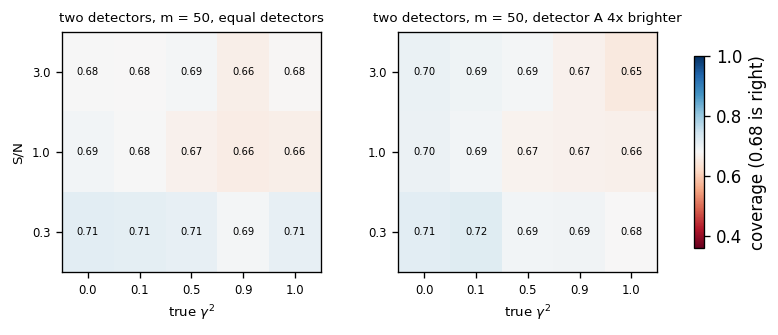

In [15]:
def simulate_two_detectors(signal_power, coherence, m, n_sim, noise=(1.0, 1.0, 1.0, 1.0), phase=0.5):
    # Amplitudes of bands 1 and 2 in detectors A and B; noise = (A1, B1, A2, B2) noise levels
    soft = complex_gaussian((n_sim, m))
    hard = np.sqrt(coherence) * soft * np.exp(-1j * phase) + np.sqrt(1 - coherence) * complex_gaussian((n_sim, m))
    signals = np.sqrt(signal_power) * np.array([soft, soft, hard, hard])
    return [s + np.sqrt(n) * complex_gaussian((n_sim, m)) for s, n in zip(signals, noise)]


def cross_matrix(a1, b1, a2, b2):
    # Averaged S11, S22, S12 and the four power spectra
    s11 = np.mean(np.conj(a1) * b1, axis=-1).real
    s22 = np.mean(np.conj(a2) * b2, axis=-1).real
    s12 = np.mean(np.conj(a1) * b2 + np.conj(b1) * a2, axis=-1) / 2
    return s11, s22, s12, [np.mean(np.abs(a) ** 2, axis=-1) for a in (a1, b1, a2, b2)]


snrs2, cohs2, m2, n_sim = [0.3, 1.0, 3.0], [0.0, 0.1, 0.5, 0.9, 1.0], 50, 2000
setups = {"equal detectors": (1.0, 1.0, 1.0, 1.0), "detector A 4x brighter": (0.5, 2.0, 0.5, 2.0)}
cov_two = {}
with warnings.catch_warnings(), np.errstate(all="ignore"):
    warnings.simplefilter("ignore")
    for name, noise in setups.items():
        cov = np.zeros((len(snrs2), len(cohs2)))
        for j, snr in enumerate(snrs2):
            for k, c in enumerate(cohs2):
                amplitudes = simulate_two_detectors(snr, c, m2, n_sim, noise)
                _, lower, upper = cross_detector_coherence(*cross_matrix(*amplitudes), m2, return_interval=True)
                defined = ~np.isnan(lower)  # NaN where a cospectrum is not positive
                cov[j, k] = coverage(lower[defined], upper[defined], c)
        cov_two[name] = cov

coverage_maps([list(cov_two.values())], [f"two detectors, m = {m2}"], "S/N", list(setups), cohs2, snrs2)

The coverage stays close to 0.68 for equal and different detectors. Here $S/N$ is the source
power divided by a noise level of 1; in the unequal setup detector A has noise 0.5 and detector B
noise 2.

## 7. Summary and recipe

* **The estimate.** `intrinsic_coherence` subtracts the full bias $\langle P_1\rangle\langle P_2\rangle/m$
  of the squared cross spectrum, which includes the incoherent part of the source variability.
  On average, it gives the true coherence. It can be negative when the coherence is small:
  keep those values, they are needed for correct averages.
* **The error bars.** Use `return_interval=True` for the 1-sigma interval, which can be
  asymmetric and can extend outside [0, 1]. It contains the true value about 68% of the time
  from no coherence to full coherence, and is a bit conservative only when the coherence can
  hardly be measured. `return_uncertainty=True` gives half its width.
* **Two detectors.** If two detectors observe the source simultaneously, build
  `cross_detector_spectral_matrix` and use `cross_detector_coherence`: no noise level is needed,
  so dead time and other distortions of the noise do not matter. Dead time still mixes the
  recorded energy bands slightly, which changes the coherence of the recorded signal.
* **Averaging.** Average over segments and/or frequency bins *before* calculating the coherence.
  The number of averaged values, $m$, is the number of segments times the number of frequency
  bins.
* **Limits.** The calculation assumes Gaussian Fourier amplitudes: average at least a few tens of
  segments. With only 10, the two-detector interval can be too narrow at high coherence (coverage
  down to about 0.56).

```python
# One detector, known noise levels
coh, lower, upper = intrinsic_coherence(cross, power1, power2, noise1, noise2, n_ave, return_interval=True)
# or, from an AveragedCrossspectrum
coh, lower, upper = cs.intrinsic_coherence(return_interval=True)

# Two detectors, no noise level
matrix = cross_detector_spectral_matrix(soft_a, hard_a, soft_b, hard_b, segment_size=64.0, dt=dt)
coh, lower, upper = cross_detector_coherence(
    matrix.power1, matrix.power2, matrix.cross_power, matrix.auto_powers, matrix.m, return_interval=True
)
```

**References**

* Bachetti, M., et al. 2015, ApJ 800, 109: the cospectrum of two detectors.
* Vaughan, B. A., & Nowak, M. A. 1997, ApJ 474, L43: the intrinsic coherence.
* Bendat, J. S., & Piersol, A. G., *Random Data: Analysis and Measurement Procedures*: the error
  on the coherence without noise.